# Asistente visual de enfermedades del arroz
**Proyecto final del diplomado ML/DL · Jenny Bareiro · 6 de octubre de 2026**

Este prototipo compara fotografías de arroz con tres etiquetas del conjunto público: **blast (piricularia), brown_spot (mancha parda) y normal (aspecto normal)**. Su objetivo es evaluar una clasificación visual y demostrar una aplicación. No predice brotes futuros ni mide resistencia genética.

Módulos: **M5**, extracción visual con una red preentrenada; **M2**, `ColumnTransformer + Pipeline`; **M3**, clasificación supervisada.

**Ejecución completa:** colocar los cinco archivos juntos, instalar las dependencias del README y ejecutar todas las celdas en orden. Se descargan unos 820 MB de datos públicos; estos archivos quedan en `datos_arroz/` y no forman parte del ZIP. La muestra de 100 filas permite probar el modelo guardado, pero no reemplaza los datos usados para entrenar.

In [1]:
from pathlib import Path
import os, json, base64, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
from sklearn.model_selection import train_test_split
import app

DATOS = Path(os.environ.get("ARROZ_DATA_DIR", "datos_arroz")).resolve()
SEED = app.SEED
print("Semilla:", SEED)
print("Dataset:", app.DATASET)
print("Revisión:", app.REVISION)
print("Versiones:", {p: importlib.metadata.version(p) for p in ["torch", "torchvision", "scikit-learn", "numpy", "pandas"]})

Semilla: 42
Dataset: Project-AgML/paddy_disease_classification
Revisión: e7cd4e729b637a24d3b66fbf3cf2ead4761d5c33
Versiones: {'torch': '2.5.1+cpu', 'torchvision': '0.20.1+cpu', 'scikit-learn': '1.8.0', 'numpy': '2.3.5', 'pandas': '2.2.3'}


## 1. Problema, datos y objetivo

Un técnico debe revisar fotografías de síntomas en arroz; una herramienta visual podría ayudar a ordenar esa revisión. Evaluamos si patrones de las imágenes permiten distinguir las tres categorías, usando etiquetas ya disponibles.

**Objetivo:** construir un prototipo reproducible y evaluar F1 macro y recall de piricularia en imágenes reservadas. Metas iniciales de comparación: F1 macro ≥ 0,85 y recall de piricularia ≥ 0,90; no se garantiza alcanzarlas.

Paddy Doctor se recopiló en Tamil Nadu, India, con anotación visual asistida por un oficial agrícola. La copia de Project-AgML contiene 10.407 imágenes y diez categorías; seleccionamos tres. No contiene identificadores de planta, parcela o sesión. El origen y las condiciones limitan la extrapolación a Paraguay.

Fuentes: [dataset utilizado](https://huggingface.co/datasets/Project-AgML/paddy_disease_classification), [recolección original](https://paddydoc.github.io/dataset/). No se emplean datos del trabajo de la autora.

In [2]:
data, audit = app.prepare_data(DATOS)
print("Imágenes seleccionadas antes de deduplicar:", audit["imagenes_utilizables"])
print("Copias exactas redundantes:", audit["coincidencias_exactas"])
print("Imágenes únicas:", len(data))
print("Grupos de similitud:", data["grupo"].nunique())
print("Imágenes no legibles:", len(audit["imagenes_no_legibles"]))
print("Grupos con etiquetas contradictorias:", len(audit["grupos_con_multiples_clases_requieren_revision"]))
display(data[["id", "clase", "ancho", "alto", "grupo", "split"]].head())

,id,clase,ancho,alto,grupo,split
0,train-00000-of-00002_r02258,brown_spot,480,640,g00000,train
1,train-00000-of-00002_r02259,brown_spot,480,640,g00757,val
2,train-00000-of-00002_r02260,brown_spot,480,640,g00002,train
3,train-00000-of-00002_r02261,brown_spot,480,640,g00003,val
4,train-00000-of-00002_r02262,brown_spot,480,640,g00004,train


Revisado: train-00000-of-00002.parquet
Revisado: train-00001-of-00002.parquet
Imágenes seleccionadas antes de deduplicar: 4467
Copias exactas redundantes: 37
Imágenes únicas: 4430
Grupos de similitud: 3714
Imágenes no legibles: 0
Grupos con etiquetas contradictorias: 0


## 2. Separación y revisión

Eliminamos copias exactas por SHA256. Agrupamos imágenes con un resumen visual parecido (pHash, distancia de Hamming ≤ 4) y mantenemos cada grupo en una sola partición. Esta agrupación reduce coincidencias entre entrenamiento y prueba, pero no demuestra independencia de plantas ni parcelas.

La división estratificada de grupos usa aproximadamente 70 % para entrenamiento, 15 % para validación y 15 % para prueba. Las proporciones de imágenes pueden variar porque un grupo puede tener varias fotos. **Los modelos se eligen con validación; la prueba se utiliza una vez al cerrar la elección.**

clase,blast,brown_spot,normal,Total
split,,,,
train,1197,668,1213,3078
val,281,142,262,685
test,250,143,274,667


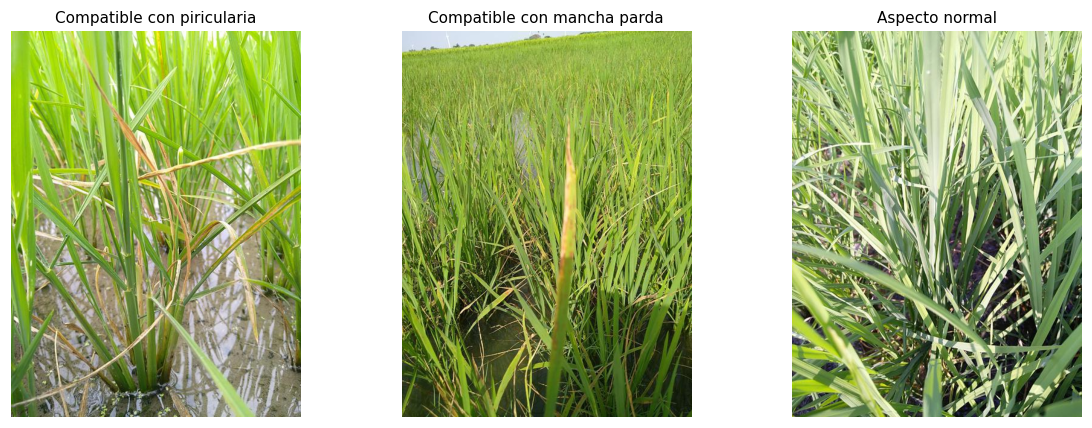

Porcentajes de imágenes: {'train': 69.5, 'val': 15.5, 'test': 15.1}
Comprobación: los grupos y las copias detectadas no cruzan entre particiones.


In [3]:
counts = pd.crosstab(data["split"], data["clase"]).reindex(["train", "val", "test"])
counts["Total"] = counts.sum(axis=1)
display(counts)
print("Porcentajes de imágenes:", (100 * counts["Total"] / len(data)).round(1).to_dict())
assert data.groupby("grupo")["split"].nunique().max() == 1
assert data.groupby("sha256")["split"].nunique().max() == 1
print("Comprobación: los grupos y las copias detectadas no cruzan entre particiones.")
fig, axes = plt.subplots(1, 3, figsize=(11, 4))
for ax, label in zip(axes, app.CLASSES):
    row = data[(data["split"] == "train") & (data["clase"] == label)].iloc[0]
    with Image.open(row["imagen_path"]) as image:
        ax.imshow(image.convert("RGB"))
    ax.set_title(app.NAMES[label], fontsize=10); ax.axis("off")
plt.tight_layout(); plt.show()

## 3. Convertir fotografías a características — M5

MobileNetV3 Small, preentrenada con ImageNet, genera 576 características por fotografía. Sus pesos permanecen fijos; no entrenamos una red desde cero. Se usa el procesamiento oficial: redimensionamiento a 256, recorte central 224 × 224 y normalización RGB.

Esto reduce el costo del entrenamiento. El recorte puede omitir síntomas periféricos y las características de ImageNet no fueron aprendidas específicamente para estas enfermedades. Los números extraídos no tienen una interpretación agronómica individual.

In [4]:
X, extractor = app.extract_features(data, DATOS)
print("Matriz de características:", X.shape)
print("Valores faltantes:", int(X.isna().sum().sum()))
assert np.isfinite(X.to_numpy()).all()
display(X.iloc[:3, :6])

,f_000,f_001,f_002,f_003,f_004,f_005
0,-0.118729,-0.108808,-0.215088,-0.034764,-0.064853,-0.075361
1,-0.107135,0.067439,0.059452,-0.080705,-0.082388,-0.167977
2,-0.054029,-0.148226,-0.225512,-0.075101,-0.087238,-0.143021


Descargado: mobilenet_v3_small-047dcff4.pth
Características: 32/4430
Características: 352/4430
Características: 672/4430
Características: 992/4430
Características: 1312/4430
Características: 1632/4430
Características: 1952/4430
Características: 2272/4430
Características: 2592/4430
Características: 2912/4430
Características: 3232/4430
Características: 3552/4430
Características: 3872/4430
Características: 4192/4430
Matriz de características: (4430, 576)
Valores faltantes: 0


## 4. Procesamiento y comparación — M2 y M3

`ColumnTransformer` selecciona únicamente las 576 características; quedan fuera etiqueta, identificador y grupo. Un `Pipeline` encadena imputación, escalado y clasificador. La imputación y el escalado se ajustan con entrenamiento al comparar modelos.

Se comparan una referencia que siempre predice la clase mayoritaria, regresión logística con C = 0,1 / 1 / 10 y Random Forest con dos tamaños mínimos de hoja. Se elige por **F1 macro de validación**, dando igual peso a las tres categorías. Después se reentrena la configuración elegida con entrenamiento + validación y se evalúa la prueba reservada. No se cambia el modelo por lo observado en prueba.

In [5]:
pipeline_example = app.make_pipeline(__import__("sklearn").linear_model.LogisticRegression(max_iter=2000))
print(pipeline_example)
final_model, comparison, chosen, test_metrics, baseline_metrics = app.train_models(X, data)
display(comparison.round(4))
print("Elección cerrada con validación:", chosen)
comparison.to_csv(DATOS / "comparacion_validacion.csv", index=False)

,modelo,f1_macro_val,recall_blast_val,segundos_ajuste
0,Logistica_C0.1,0.8974,0.9181,4.3292
1,Logistica_C10,0.8886,0.9110,4.8812
2,Logistica_C1,0.8851,0.9004,5.4605
3,RandomForest_hoja5,0.8507,0.9110,1.3907
4,RandomForest_hoja2,0.8506,0.9359,1.4903
5,Referencia,0.1844,0.0000,0.1239


Pipeline(steps=[('procesamiento',
                 ColumnTransformer(transformers=[('visuales',
                                                  Pipeline(steps=[('imputacion',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('escala',
                                                                   StandardScaler())]),
                                                  ['f_000', 'f_001', 'f_002',
                                                   'f_003', 'f_004', 'f_005',
                                                   'f_006', 'f_007', 'f_008',
                                                   'f_009', 'f_010', 'f_011',
                                                   'f_012', 'f_013', 'f_014',
                                                   'f_015', 'f_016', 'f_017',
                                                   'f_018', 'f_019', 'f_020',
          

## 5. Evaluación final

F1 macro combina precisión y recall y pondera igual cada clase. El recall de piricularia mide qué proporción de fotografías etiquetadas como blast fue reconocida. La precisión mide qué proporción de predicciones de una clase coincide con la etiqueta visual del conjunto.

Estas mediciones describen este conjunto de prueba; no prueban eficacia en campos de Paraguay ni confirmación del patógeno.

,precision,recall,f1-score,support
blast,0.8947,0.8840,0.8893,250.0
brown_spot,0.8231,0.8462,0.8345,143.0
normal,0.9451,0.9416,0.9433,274.0


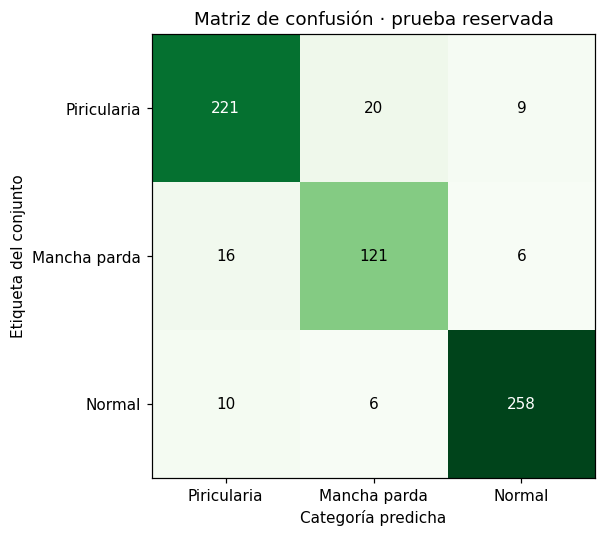

Imágenes de prueba: 667
F1 macro del modelo: 0.889
F1 macro de la referencia: 0.1818
Meta F1 macro 0,85: alcanzada
Meta recall blast 0,90: no alcanzada


In [6]:
test_mask = data["split"].eq("test")
report = pd.DataFrame(test_metrics["reporte"]).T
print("Imágenes de prueba:", int(test_mask.sum()))
print("F1 macro del modelo:", round(test_metrics["f1_macro"], 4))
print("F1 macro de la referencia:", round(baseline_metrics["f1_macro"], 4))
display(report.loc[app.CLASSES, ["precision", "recall", "f1-score", "support"]].round(4))
print("Meta F1 macro 0,85:", "alcanzada" if test_metrics["f1_macro"] >= .85 else "no alcanzada")
print("Meta recall blast 0,90:", "alcanzada" if test_metrics["reporte"]["blast"]["recall"] >= .90 else "no alcanzada")
cm = np.asarray(test_metrics["matriz_confusion"])
fig, ax = plt.subplots(figsize=(6, 5)); ax.imshow(cm, cmap="Greens")
ax.set_xticks(range(3), labels=["Piricularia", "Mancha parda", "Normal"])
ax.set_yticks(range(3), labels=["Piricularia", "Mancha parda", "Normal"])
ax.set_xlabel("Categoría predicha"); ax.set_ylabel("Etiqueta del conjunto")
ax.set_title("Matriz de confusión · prueba reservada")
for i in range(3):
    for j in range(3):
        ax.text(j, i, str(cm[i,j]), ha="center", va="center", color="white" if cm[i,j] > cm.max()/2 else "black")
plt.tight_layout(); plt.show()

,id,clase,prediccion
65,train-00000-of-00002_r02323,brown_spot,blast
116,train-00000-of-00002_r02374,brown_spot,blast
228,train-00000-of-00002_r02486,brown_spot,normal
255,train-00000-of-00002_r02513,brown_spot,blast
277,train-00000-of-00002_r02536,brown_spot,blast
379,train-00000-of-00002_r02638,brown_spot,blast


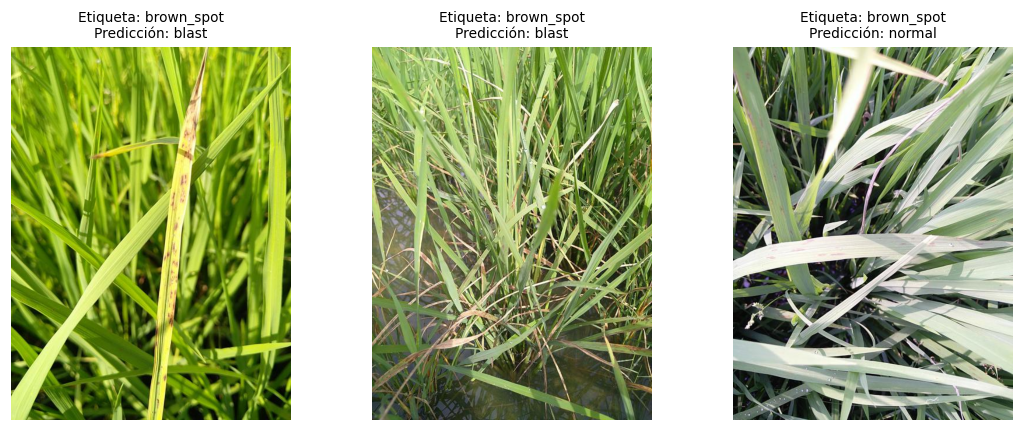

Errores en prueba: 67


In [7]:
predictions = final_model.predict(X.loc[test_mask])
errors = data.loc[test_mask].copy()
errors["prediccion"] = predictions
errors = errors[errors["clase"] != errors["prediccion"]]
print("Errores en prueba:", len(errors))
display(errors[["id", "clase", "prediccion"]].head(6))
if len(errors):
    fig, axes = plt.subplots(1, min(3, len(errors)), figsize=(10, 4), squeeze=False)
    for ax, (_, row) in zip(axes.flat, errors.head(3).iterrows()):
        with Image.open(row["imagen_path"]) as image:
            ax.imshow(image.convert("RGB"))
        ax.set_title(f"Etiqueta: {row['clase']}\nPredicción: {row['prediccion']}", fontsize=9); ax.axis("off")
    plt.tight_layout(); plt.show()

## 6. Guardado, recarga y muestra de 100 filas

`model.pkl` contiene los pesos del extractor fijo, el pipeline entrenado y los resultados. No depende de descargar los pesos para inferencia.

`datos_muestra.csv` contiene **100 fotografías de prueba**, seleccionadas de forma estratificada con semilla fija, sus características y su etiqueta. La imagen original se codifica como texto base64 para que la aplicación tenga ejemplos sin incluir todo el conjunto. La muestra sirve para inferencia y comprobación; no se utiliza para entrenar ni se escogen solo aciertos.

In [8]:
bundle = app.save_bundle(Path("model.pkl"), final_model, extractor, audit, data,
                         comparison, chosen, test_metrics, baseline_metrics)
loaded, loaded_net, loaded_transform = app.load_bundle(Path("model.pkl"))
loaded_predictions = loaded["pipeline"].predict(X.loc[test_mask])
assert np.array_equal(loaded_predictions, predictions)
print("Recarga: se reproducen todas las predicciones de prueba.")
indices = data.index[test_mask].to_numpy()
sample_indices, _ = train_test_split(indices, train_size=100, random_state=SEED,
                                   stratify=data.loc[indices, "clase"])
sample_indices = np.sort(sample_indices)
sample = data.loc[sample_indices, ["id", "clase", "grupo", "split"]].reset_index(drop=True)
sample["prediccion_guardada"] = final_model.predict(X.loc[sample_indices])
sample = pd.concat([sample, X.loc[sample_indices].reset_index(drop=True)], axis=1)
sample["imagen_jpeg_base64"] = [base64.b64encode(Path(data.loc[i, "imagen_path"]).read_bytes()).decode("ascii") for i in sample_indices]
assert len(sample) == 100 and sample["split"].eq("test").all()
sample.to_csv("datos_muestra.csv", index=False, float_format="%.9g")
reloaded_sample = pd.read_csv("datos_muestra.csv")
assert np.array_equal(loaded["pipeline"].predict(reloaded_sample[app.FEATURES]), sample["prediccion_guardada"])
for label in app.CLASSES:
    row = data[(data["split"] == "test") & (data["clase"] == label)].iloc[0]
    with Image.open(row["imagen_path"]) as image:
        predicted, scores = app.predict_image(image, loaded, loaded_net, loaded_transform)
    numeric_prediction = final_model.predict(X.loc[[row.name]])[0]
    assert predicted == numeric_prediction
    print(label, "→", predicted, "; puntajes:", {k: round(v, 3) for k, v in scores.items()})
print("Muestra:", reloaded_sample.shape, "; 100 filas de datos más encabezado.")
print("Tamaño modelo MB:", round(Path("model.pkl").stat().st_size / 1e6, 2))
print("Tamaño muestra MB:", round(Path("datos_muestra.csv").stat().st_size / 1e6, 2))

Recarga: se reproducen todas las predicciones de prueba.
blast → normal ; puntajes: {'blast': 0.088, 'brown_spot': 0.041, 'normal': 0.87}
brown_spot → brown_spot ; puntajes: {'blast': 0.002, 'brown_spot': 0.998, 'normal': 0.0}
normal → normal ; puntajes: {'blast': 0.015, 'brown_spot': 0.018, 'normal': 0.967}
Muestra: (100, 582) ; 100 filas de datos más encabezado.
Tamaño modelo MB: 3.55
Tamaño muestra MB: 11.35


## 7. Demostración y tres escenarios económicos

Abrir una terminal en esta carpeta y ejecutar `python -m streamlit run app.py`. Cargar una foto o elegir uno de los ejemplos del CSV. El puntaje por categoría no representa certeza diagnóstica y aún no se validó el rechazo de fotografías de otros cultivos o enfermedades.

El beneficio económico se plantea como **hipótesis de ahorro de tiempo en un año**. No se midió durante este proyecto. Los minutos ahorrados son netos, incluyendo la revisión del técnico. Supuestos ilustrativos: Gs. 50.000 por hora, inversión inicial Gs. 2.000.000 y operación anual Gs. 500.000.

Ahorro anual = consultas × minutos netos / 60 × valor de la hora. ROI del primer año = (ahorro − inversión − operación) / (inversión + operación) × 100. El tiempo liberado puede tener valor sin traducirse en una reducción efectiva de gastos.

In [9]:
roi = app.roi_scenarios()
display(roi.round(1))
print("Los tres escenarios son supuestos; el proyecto no ha medido un retorno económico real.")

,escenario,consultas_anuales,minutos_netos_ahorrados,costo_hora_Gs,inversion_inicial_Gs,operacion_anual_Gs,ahorro_anual_Gs,beneficio_neto_Gs,ROI_primer_anio_pct
0,Conservador,500,1,50000,2000000,500000,416666.7,-2083333.3,-83.3
1,Intermedio,1500,3,50000,2000000,500000,3750000.0,1250000.0,50.0
2,Favorable,3000,4,50000,2000000,500000,10000000.0,7500000.0,300.0


Los tres escenarios son supuestos; el proyecto no ha medido un retorno económico real.


## 8. Conclusión y próximos pasos

El modelo elegido con validación, MobileNetV3 Small fija + regresión logística C = 0,1, obtuvo **F1 macro de 0,8890** y **600 aciertos de 667 fotografías de prueba (89,96 %)**. La referencia de clase mayoritaria obtuvo F1 macro de 0,1818. Se alcanzó la meta principal de F1 ≥ 0,85.

El **recall de piricularia fue 88,4 % (221/250)**: no se alcanzó la meta adicional del 90 %. Hubo 29 fotos de esta categoría confundidas, nueve con normal. Mancha parda tuvo el menor F1 de las tres categorías (0,8345). No se cambió el modelo tras observar la prueba. Estos resultados respaldan una prueba de concepto sobre etiquetas visuales de este conjunto, sin demostrar utilidad local ni diagnóstica.

Limitaciones: anotación visual, origen geográfico único, tres categorías, ausencia de identificadores de plantas/sesiones y recorte central de imagen. Los puntajes no se calibraron. No hay validación de fotos fuera de distribución ni ensayo de utilidad operativa. Los tres escenarios económicos son hipótesis; incluyen un escenario conservador con ROI negativo.

Próximos pasos:
1. Recopilar y etiquetar fotografías locales con especialistas; separar prueba por parcela o sesión.
2. Ampliar las categorías y estudiar rechazo de fotos ajenas al alcance y calibración de puntajes.
3. Medir en un piloto tiempo de revisión, errores y costos para contrastar los tres escenarios.

**Entrega:** README.md, notebook_final.ipynb, model.pkl, datos_muestra.csv y app.py. El repositorio GitHub y el video, si corresponde, se preparan con estos mismos archivos. No incluir la carpeta datos_arroz ni el entorno Python en el ZIP.
